<h1 align="center" style="color:#1f77b4;">
    Hand Written Digits Classification
</h1>


<h7 align="center" style="color:#1f7;">
    Data Loading, Preperation and Exploration
</h7>


In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import torch
import torch.nn as nn
import torch.optim as optim 
from torchvision import datasets
from torchvision.transforms import ToTensor,Normalize,Compose
from torch.utils.data import DataLoader

In [26]:
if torch.cuda.is_available():
    device=torch.device("cuda")
else:
    device=torch.device("cpu")

print(f"Device is '{device}'")

Device is 'cuda'


In [27]:
transforms= Compose(
    [
        ToTensor(),
        Normalize(0.5,0.5)
    ]
)

train_data=datasets.MNIST(
    root="Data",
    download=True,
    transform=transforms,
    train=True
)

test_data=datasets.MNIST(
    root="Data",
    download=True,
    transform=transforms,
    train=False
)

In [28]:
len(train_data)

60000

In [29]:
len(test_data)

10000

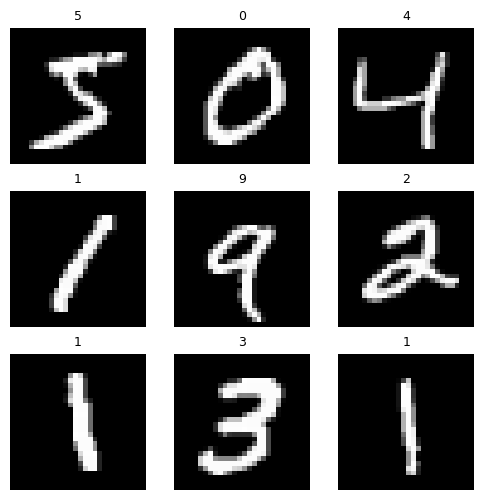

In [30]:
fig, axes = plt.subplots(3, 3, figsize=(6, 6))

for i, ax in enumerate(axes.flat):
    image, label =train_data[i]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(label, fontsize=9)
    ax.axis("off")

plt.show()

In [31]:
train_data_loader=DataLoader(train_data,batch_size=64,shuffle=True)
test_data_loader=DataLoader(test_data,batch_size=64,shuffle=True)
data_iter=iter(train_data)
images,labels=next(data_iter)

<h7 align="center" style="color:#1f7;">
    Neural Network Training and Evaluation
</h7>


5